<a href="https://colab.research.google.com/github/rawan587/Project_AI/blob/main/geneticAlgorithm.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import pandas as pd
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score

In [ ]:
df = pd.read_csv("/content/breast_cancer_wisconsin_clean.csv")

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
df.head()

,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave_points_mean,symmetry_mean,fractal_dimension_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave_points_worst,symmetry_worst,fractal_dimension_worst,diagnosis
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,M
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,M
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,M
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,M
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,M


In [ ]:
df.shape

(569, 31)

In [ ]:
X_df = df.drop(columns=["diagnosis"])
y = (df["diagnosis"] == "M").astype(int).values

feature_names = X_df.columns.to_numpy()
X = X_df.values
N_FEATURES = X.shape[1]

print("Number of features:", N_FEATURES)
print(list(feature_names))

Number of features: 30
['radius_mean', 'texture_mean', 'perimeter_mean', 'area_mean', 'smoothness_mean', 'compactness_mean', 'concavity_mean', 'concave_points_mean', 'symmetry_mean', 'fractal_dimension_mean', 'radius_se', 'texture_se', 'perimeter_se', 'area_se', 'smoothness_se', 'compactness_se', 'concavity_se', 'concave_points_se', 'symmetry_se', 'fractal_dimension_se', 'radius_worst', 'texture_worst', 'perimeter_worst', 'area_worst', 'smoothness_worst', 'compactness_worst', 'concavity_worst', 'concave_points_worst', 'symmetry_worst', 'fractal_dimension_worst']


In [ ]:
SEED= 42
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED)

print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Malignant ratio  train/test:", y_train.mean().round(3), "/", y_test.mean().round(3))

Train: (455, 30) | Test: (114, 30)
Malignant ratio  train/test: 0.374 / 0.368


In [ ]:
POP_SIZE = 30
N_GENERATIONS = 30
ALPHA = 0.01
CLASSIFIER = "tree"

rng = np.random.default_rng(SEED)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

def build_model(name):
  return DecisionTreeClassifier(random_state=SEED)

model = build_model(CLASSIFIER)
_cache = {}
print("Fitness classifier:", CLASSIFIER)

Fitness classifier: tree


In [ ]:
example = np.zeros(N_FEATURES, dtype=int)
example[[0, 3, 7]] = 1

print("Chromosome:", example)
print("Selected features:", feature_names[example.astype(bool)])

Chromosome: [1 0 0 1 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]
Selected features: ['radius_mean' 'area_mean' 'concave_points_mean']


In [ ]:
def init_population(pop_size, n_features):
    pop = rng.integers(0, 2, size=(pop_size, n_features))
    for ind in pop:
        if ind.sum() == 0:
            ind[rng.integers(n_features)] = 1
    return pop

population = init_population(POP_SIZE, N_FEATURES)
print("Population shape:", population.shape)
print("First individual:", population[0])

Population shape: (30, 30)
First individual: [0 1 1 0 0 1 0 1 0 0 1 1 1 1 1 1 1 0 1 0 1 0 0 1 1 1 0 1 1 0]


In [ ]:
def decode(chromosome):

    return feature_names[np.asarray(chromosome).astype(bool)]

print(len(decode(population[0])), "features selected in individual 0")

18 features selected in individual 0


In [ ]:
def fitness(chromosome):
    chromosome = np.asarray(chromosome)
    key = chromosome.tobytes()
    if key in _cache:
        return _cache[key]

    if chromosome.sum() == 0:
        return 0.0

    mask = chromosome.astype(bool)
    acc = cross_val_score(model, X_train[:, mask], y_train, cv=cv, scoring="accuracy").mean()
    penalty = ALPHA * (chromosome.sum() / N_FEATURES)
    score = acc - penalty

    _cache[key] = score
    return score


print("Fitness of individual 0:", round(fitness(population[0]), 4))

Fitness of individual 0: 0.9303


In [ ]:
baseline_acc = cross_val_score(model, X_train, y_train, cv=cv, scoring="accuracy").mean()
print(f"Baseline CV accuracy on train (all {N_FEATURES} features): {baseline_acc:.4f}")

Baseline CV accuracy on train (all 30 features): 0.9231


In [ ]:
def evaluate_population(pop):

    return np.array([fitness(ind) for ind in pop])

def get_best_individual(pop, scores):

    i = int(np.argmax(scores))
    return pop[i].copy(), scores[i]

scores = evaluate_population(population)
best_ind, best_score = get_best_individual(population, scores)

print("Generation 0:")
print(f"  best fitness = {scores.max():.4f}")
print(f"  avg  fitness = {scores.mean():.4f}")
print(f"  best individual has {best_ind.sum()} features")

Generation 0:
  best fitness = 0.9460
  avg  fitness = 0.9224
  best individual has 17 features


In [ ]:
CROSSOVER_RATE = 0.8
MUTATION_RATE = 0.02
ELITISM = 2

In [ ]:
# SELECTION metrics? different type of selections starategies

In [ ]:
def rouletteSelection(pop, scores):
    probs = scores / scores.sum()
    return pop [rng.choice(len(pop),  p=probs)].copy ()


In [ ]:
def tournamentSelection(pop, scores, k=3):
    index = rng.choice(len(pop),size = k, replace=False)
    return pop [index[np.argmax(scores[index])]].copy()

In [ ]:
def rankSelection (pop, scores):
    ranks = np.empty (len (scores), dtype = float)
    ranks [np.argsort(scores)] = np.arange(1,len(scores)+1)
    probs = ranks / ranks.sum ()
    return pop [rng.choice(len(pop), p = probs)].copy()

In [ ]:
SELECTIONS = {
    "roulette": rouletteSelection,
    "tournament": tournamentSelection,
    "rank": rankSelection
}

In [ ]:
# CROSSOVER DIFFERENT STRARTEGIES

In [ ]:
def onePointCOver(parent1, parent2):
    pt = rng.integers(1, len(parent1))
    c1 = np.concatenate ((parent1[:pt],parent2[pt:]))
    c2 = np.concatenate ((parent2[:pt],parent1[pt:]))
    return c1 , c2

In [ ]:
def twoPointCOver (parent1,parent2) :
    pt1, pt2 = sorted (rng.choice(np.arange (1,len(parent1)),size =2, replace=False)) #two points to cut
    c1 , c2= parent1.copy(), parent2.copy()
    c1 [pt1:pt2], c2 [pt1:pt2] = parent2[pt1: pt2].copy(), parent1[pt1:pt2].copy()
    return c1 , c2

In [ ]:
def uniCOver(parent1,parent2, swap_prob=0.5) :
    swap = rng.random (len(parent1)) < swap_prob
    c1 =np.where (swap,parent2,parent1)
    c2= np.where (swap, parent1,parent2)
    return c1 , c2

In [ ]:
CROSSOVERS ={
    "onePoint": onePointCOver,
    "twoPoint": twoPointCOver,
    "uniform": uniCOver}

In [ ]:
#MUTATATIONs strateigeies

In [ ]:
def _repair (chromosome):
    if chromosome.sum() == 0:
        chromosome[rng.integers (len(chromosome))] = 1
    return chromosome

In [ ]:
def bitFlipMutation(chromosome, rate = None): # flips with probabilty of rate
    rate = MUTATION_RATE if rate is None else rate
    chromosome = chromosome.copy ()
    flip = rng.random (len(chromosome)) <rate
    chromosome [ flip] =1-chromosome [flip]
    return _repair(chromosome) #to make sure the chormosome is never 0

In [ ]:
def randMutation (chromosome, rate =None):
    rate = MUTATION_RATE if rate is None else rate
    chromosome = chromosome.copy ()
    chosenOne= rng.random(len (chromosome)) <rate
    chromosome [ chosenOne] = rng.integers ( 0, 2 , size =chosenOne.sum())
    return _repair (chromosome)

In [ ]:
MUTATIONS ={
    "bitflip" : bitFlipMutation,
    "random" : randMutation

}

In [ ]:
#running the genetic algo Func

In [ ]:
def run_ga(selectionFN,crossoverFN,mutationFN, seed= SEED, verbose =False):

    global rng; rng= np.random.default_rng(seed);

    pop = init_population(POP_SIZE, N_FEATURES)
    history = []
    best_ind, best_score = None, -1

    for gen in range(N_GENERATIONS):
        scores = evaluate_population(pop)
        gen_best_ind, gen_best_score = get_best_individual(pop, scores)

        if gen_best_score > best_score:
            best_ind, best_score = gen_best_ind, gen_best_score

        history.append({"generation": gen,"best_fitness": scores.max(),
                        "avg_fitness": scores.mean(),
                        "n_features": int(gen_best_ind.sum())})

        if verbose == True:
            print(f"Generation: {gen:02d} || best fitness={scores.max():.4f} || average vitness={scores.mean():.4f} "
                  f"|| num features={int(gen_best_ind.sum())}")


        order = np.argsort(scores)[::-1]
        new_pop = [pop[i].copy() for i in order[:ELITISM]]


        while len(new_pop) < POP_SIZE:
            p1 = selectionFN(pop, scores)
            p2 = selectionFN(pop, scores)


            if rng.random () < CROSSOVER_RATE:
                c1, c2 =crossoverFN(p1,p2)
            else:
                c1 ,c2 =p1.copy(), p2.copy()


            new_pop.append(mutationFN(c1))
            if len(new_pop) < POP_SIZE:
                new_pop.append(mutationFN(c2))

        pop = np.array(new_pop)

    return best_ind, best_score, pd.DataFrame(history)

In [ ]:
SEEDS=[42,7,125]
results=[]

for s in SEEDS:
    best, best_fit, history = run_ga(SELECTIONS["tournament"],CROSSOVERS["onePoint"],MUTATIONS["bitflip"],s,False)
    results.append((best_fit, best,history,s))
    print(f"seed is {s}, fitnees is {best_fit}, number of features is {best.sum()}")

best_fit,best,history,best_seed = max (results, key = lambda r:r[0])
print("Best seed:", best_seed)



mask = best.astype(bool)
best_acc = cross_val_score(model, X_train[:, mask], y_train, cv=cv, scoring="accuracy").mean()

print("\nBest chromosome:", best.tolist())
print(f"Selected {mask.sum()} / {N_FEATURES} features:")
for name in decode(best):
    print("  -", name)
print(f"\nTrain CV accuracy (selected): {best_acc:.4f}")
print(f"Train CV accuracy (all)     : {baseline_acc:.4f}")

seed is 42, fitnees is 0.9674285714285715, number of features is 12
seed is 7, fitnees is 0.9601684981684983, number of features is 14
seed is 125, fitnees is 0.9601684981684983, number of features is 14
Best seed: 42

Best chromosome: [0, 1, 0, 0, 1, 0, 0, 1, 1, 0, 1, 0, 0, 0, 0, 1, 0, 1, 0, 1, 1, 1, 0, 0, 1, 0, 1, 0, 0, 0]
Selected 12 / 30 features:
  - texture_mean
  - smoothness_mean
  - concave_points_mean
  - symmetry_mean
  - radius_se
  - compactness_se
  - concave_points_se
  - fractal_dimension_se
  - radius_worst
  - texture_worst
  - smoothness_worst
  - concavity_worst

Train CV accuracy (selected): 0.9714
Train CV accuracy (all)     : 0.9231


In [ ]:
for s in SEEDS:
    best, best_fit, history = run_ga(SELECTIONS["roulette"],CROSSOVERS["twoPoint"],MUTATIONS["random"],s,False)
    results.append((best_fit, best,history,s))
    print(f"seed is {s}, fitnees is {best_fit}, number of features is {best.sum()}")

best_fit,best,history,best_seed = max (results, key = lambda r:r[0])
print("Best seed:", best_seed)

seed is 42, fitnees is 0.9586373626373628, number of features is 12
seed is 7, fitnees is 0.9583040293040292, number of features is 13
seed is 125, fitnees is 0.9564395604395604, number of features is 12
Best seed: 42


In [ ]:
def evaluate_on_test(chromosome, classifier_name):
    mask = np.asarray(chromosome).astype(bool)
    clf = build_model(classifier_name)
    clf.fit(X_train[:, mask], y_train)
    pred = clf.predict(X_test[:, mask])
    return accuracy_score(y_test, pred), f1_score(y_test, pred)

all_features = np.ones(N_FEATURES, dtype=int)
rows = []
for clf_name in ["knn", "tree"]:
    acc_all, f1_all = evaluate_on_test(all_features, clf_name)
    acc_sel, f1_sel = evaluate_on_test(best, clf_name)
    rows.append({"classifier": clf_name,
                 "acc (30 features)": round(acc_all, 4), "F1 (30 features)": round(f1_all, 4),
                 f"acc ({int(best.sum())} selected)": round(acc_sel, 4),
                f"F1 ({int(best.sum())} selected)": round(f1_sel, 4)})

pd.DataFrame(rows).set_index("classifier")

,acc (30 features),F1 (30 features),acc (12 selected),F1 (12 selected)
classifier,,,,
knn,0.9298,0.9048,0.9123,0.8718
tree,0.9298,0.9048,0.9123,0.8718


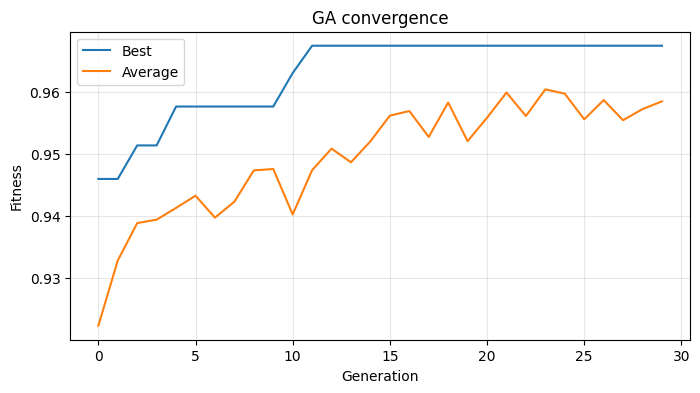

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 4))
plt.plot(history["generation"], history["best_fitness"], label="Best")
plt.plot(history["generation"], history["avg_fitness"], label="Average")
plt.xlabel("Generation"); plt.ylabel("Fitness"); plt.legend(); plt.grid(alpha=.3)
plt.title("GA convergence")
plt.show()